# Gemma 3 1B Fine-tuning with Unsloth

This notebook is the fixed version of the original Gemma 3 template:

* uses **Gemma 3 1B** (`unsloth/gemma-3-1b-it-unsloth-bnb-4bit`) instead of the 4B model;
* assumes the dependencies are already installed — the notebook runs no `pip`
  commands. See `requirements.txt` to recreate the environment;
* fixes the CSV loading (the supplied CSV header is a single quoted field);
* fixes the TRL `SFTTrainer` usage so the dataset split is passed correctly;
* fixes the inference/saving code for a text-only Gemma 3 1B model.

It uses 4-bit quantization + LoRA so it fits on a small CUDA GPU (~4 GB VRAM).

### News

**Read our [Gemma 3 blog](https://unsloth.ai/blog/gemma3) for what's new in Unsloth and our [Reasoning blog](https://unsloth.ai/blog/r1-reasoning) on how to train reasoning models.**

Visit our docs for all our [model uploads](https://docs.unsloth.ai/get-started/all-our-models) and [notebooks](https://docs.unsloth.ai/get-started/unsloth-notebooks).

## 1. Load Gemma 3 1B in 4-bit

`MAX_SEQ_LENGTH = 1024` is a safe value for a 4 GB GPU. Increase it if you have
more VRAM; lower it to 512 if you hit CUDA out-of-memory errors.

In [13]:
# Import pandas (which loads pyarrow) before Unsloth. On Windows, importing
# pyarrow after Unsloth's torch patches can crash the interpreter.
import pandas as pd
import torch

from unsloth import FastModel

print("torch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), (
    "PyTorch cannot see the GPU. If you just installed the dependencies, restart "
    "the Jupyter kernel once and run this cell again."
)

MODEL_NAME = "unsloth/gemma-3-1b-it-unsloth-bnb-4bit"
MAX_SEQ_LENGTH = 1024

model, tokenizer = FastModel.from_pretrained(
    model_name = MODEL_NAME,
    max_seq_length = MAX_SEQ_LENGTH,
    load_in_4bit = True,
    load_in_8bit = False,
    full_finetuning = False,
)

torch: 2.7.1+cu118
CUDA build: 11.8
CUDA available: True
==((====))==  Unsloth 2026.11.3: Fast Gemma3 patching. Transformers: 5.17.0.
   \\   /|    NVIDIA GeForce RTX 3050 Laptop GPU. Num GPUs = 1. Max memory: 4.0 GB. Platform: Windows.
O^O/ \_/ \    Torch: 2.7.1+cu118. CUDA: 8.6. CUDA Toolkit: 11.8. Triton: 3.3.1
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

We now add LoRA adapters so we only need to update a small amount of parameters!

In [14]:
model = FastModel.get_peft_model(
    model,
    finetune_vision_layers     = False,  # Gemma 3 1B is text-only
    finetune_language_layers   = True,
    finetune_attention_modules = True,
    finetune_mlp_modules       = True,

    r = 8,
    lora_alpha = 8,
    lora_dropout = 0,
    bias = "none",
    random_state = 3407,
    use_gradient_checkpointing = "unsloth",  # saves VRAM on a small GPU
)

## 2. Data preparation

The supplied file `dataasilida_cleaned.csv` has a header written as one quoted
field (`"input,output"`), so pandas must be told the two column names explicitly.
The rows themselves are valid quoted CSV rows.

In [15]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(
    tokenizer,
    chat_template = "gemma-3",
)

In [16]:
from datasets import Dataset
import pandas as pd

DATA_PATH = "dataasilida_cleaned.csv"

df = pd.read_csv(
    DATA_PATH,
    header = None,
    names = ["input", "output"],
    skiprows = 1,
    encoding = "utf-8",
)
df = df.dropna(subset = ["input", "output"]).astype(str)
df = df.drop_duplicates().reset_index(drop = True)

dataset = Dataset.from_pandas(df, preserve_index = False)
print(dataset)
print("Rows:", len(dataset))

Dataset({
    features: ['input', 'output'],
    num_rows: 513
})
Rows: 513


In [17]:
dataset[0]["input"]

'តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី'

In [18]:
def formatting_prompts_func(examples):
    instructions = examples["input"]
    outputs = examples["output"]
    texts = []
    for instruction, output in zip(instructions, outputs):
        messages = [
            {"role": "user", "content": instruction.strip()},
            {"role": "assistant", "content": output.strip()},
        ]
        texts.append(
            tokenizer.apply_chat_template(
                messages,
                add_generation_prompt = False,
                tokenize = False,
            )
        )
    return {"text": texts}

dataset = dataset.map(formatting_prompts_func, batched = True)
dataset[0]["text"]

Map:   0%|          | 0/513 [00:00<?, ? examples/s]

'<bos><start_of_turn>user\nតើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី<end_of_turn>\n<start_of_turn>model\nប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា គឺជាប័ណ្ណ ឬកាតអេឡិចត្រូនិក បោះផ្សាយដោយ ធនាគារ អេស៊ីលីដា ភីអិលស៊ី សម្រាប់ផ្តល់ជូនអតិថិជនក្នុងការធ្វើប្រតិបត្តិការតាមរយៈ E-Commerce ម៉ាស៊ីនឆូតកាត (POS) ម៉ាស៊ីនអេធីអឹម (ATM) ដែលមានបិទស្លាកសញ្ញា ចេស៊ីប៊ី នៅទូទាំងប្រទេស និងពាសពេញពិភពលោក ដោយធ្វើការទូទាត់សាច់ប្រាក់ចេញពីគណនីរបស់ម្ចាស់ប័ណ្ណដែលមាននៅធនាគារ អេស៊ីលីដា។<end_of_turn>\n'

## 3. Train the model

Hugging Face TRL's `SFTTrainer` is used below. The settings target a small GPU:
batch size 1 with gradient accumulation 8, 1024-token sequences, and 4-bit LoRA.

In [19]:
from trl import SFTTrainer, SFTConfig
from unsloth import is_bfloat16_supported
import inspect

sft_kwargs = dict(
    dataset_text_field = "text",
    per_device_train_batch_size = 1,
    gradient_accumulation_steps = 8,
    warmup_steps = 5,
    max_steps = 60,
    learning_rate = 2e-4,
    fp16 = not is_bfloat16_supported(),
    bf16 = is_bfloat16_supported(),
    logging_steps = 1,
    optim = "adamw_8bit",
    weight_decay = 0.01,
    lr_scheduler_type = "linear",
    seed = 3407,
    output_dir = "outputs",
    report_to = "none",
    packing = False,
)

# TRL renamed max_seq_length -> max_length in newer releases.
sft_params = inspect.signature(SFTConfig.__init__).parameters
if "max_length" in sft_params:
    sft_kwargs["max_length"] = MAX_SEQ_LENGTH
elif "max_seq_length" in sft_params:
    sft_kwargs["max_seq_length"] = MAX_SEQ_LENGTH

# Keep only arguments supported by the installed TRL version.
if not any(p.kind is inspect.Parameter.VAR_KEYWORD for p in sft_params.values()):
    sft_kwargs = {k: v for k, v in sft_kwargs.items() if k in sft_params}

trainer_kwargs = dict(
    model = model,
    train_dataset = dataset,
    args = SFTConfig(**sft_kwargs),
)
trainer_params = inspect.signature(SFTTrainer.__init__).parameters
if "processing_class" in trainer_params:
    trainer_kwargs["processing_class"] = tokenizer
else:
    trainer_kwargs["tokenizer"] = tokenizer

trainer = SFTTrainer(**trainer_kwargs)

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"]:   0%|          | 0/513 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


We also use Unsloth's `train_on_responses_only` method to only train on the
assistant outputs and ignore the loss on the user's inputs. This helps increase
accuracy of finetunes!

In [20]:
from unsloth.chat_templates import train_on_responses_only

trainer = train_on_responses_only(
    trainer,
    instruction_part = "<start_of_turn>user\n",
    response_part = "<start_of_turn>model\n",
)

Map:   0%|          | 0/513 [00:00<?, ? examples/s]

Let's verify that the instruction part is masked.

In [21]:
tokenizer.decode(trainer.train_dataset[100]["input_ids"])

'<bos><start_of_turn>user\nតើសេវានេះអាចបញ្ជាទូទាត់បានទំហំទឹកប្រាក់ប៉ុន្មានក្នុងមួយថ្ងៃ<end_of_turn>\n<start_of_turn>model\nអតិថិជនអាចបញ្ជាទូទាត់បានទំហំទឹកប្រាក់អតិបរមាក្នុងមួយថ្ងៃ USD5000 KHR20000000 THB200000។<end_of_turn>\n'

In [22]:
tokenizer.decode([
    tokenizer.pad_token_id if x == -100 else x
    for x in trainer.train_dataset[100]["labels"]
]).replace(tokenizer.pad_token, " ")

'                                   អតិថិជនអាចបញ្ជាទូទាត់បានទំហំទឹកប្រាក់អតិបរមាក្នុងមួយថ្ងៃ USD5000 KHR20000000 THB200000។<end_of_turn> '

### Show current memory stats

In [23]:
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

GPU = NVIDIA GeForce RTX 3050 Laptop GPU. Max memory = 4.0 GB.
2.006 GB of memory reserved.


### Live training-loss graph

The callback below redraws the loss inside this notebook every time the trainer
logs a step, so you can watch the run while it happens. It keeps the raw curve
(light) and an exponential moving average (solid) so the trend is visible through
the noise. If you later add an `eval_dataset`, the validation curve appears on
the same graph as orange points.

Attach the callback once, before calling `trainer.train()`.

In [24]:
import matplotlib.pyplot as plt
from transformers import TrainerCallback

try:
    from IPython.display import clear_output, display
    IN_NOTEBOOK = True
except ImportError:
    IN_NOTEBOOK = False


class LiveLossPlot(TrainerCallback):
    """Draws the training (and optional eval) loss while training runs."""

    def __init__(self, smoothing = 0.9):
        self.smoothing = smoothing
        self.steps, self.losses = [], []
        self.eval_steps, self.eval_losses = [], []

    def _draw(self):
        if not IN_NOTEBOOK:
            return

        clear_output(wait = True)
        fig, ax = plt.subplots(figsize = (8, 4))

        if self.losses:
            ax.plot(self.steps, self.losses,
                    color = "tab:blue", alpha = 0.35, label = "train loss (raw)")

            smoothed, ema = [], self.losses[0]
            for value in self.losses:
                ema = self.smoothing * ema + (1 - self.smoothing) * value
                smoothed.append(ema)
            ax.plot(self.steps, smoothed,
                    color = "tab:blue", linewidth = 2, label = "train loss (smoothed)")

            best = min(self.losses)
            ax.scatter([self.steps[self.losses.index(best)]], [best],
                       color = "tab:green", zorder = 5, label = f"best = {best:.4f}")
            ax.annotate(f"{self.losses[-1]:.4f}",
                        (self.steps[-1], self.losses[-1]),
                        textcoords = "offset points", xytext = (6, 6),
                        color = "tab:blue")

        if self.eval_losses:
            ax.plot(self.eval_steps, self.eval_losses, "o-",
                    color = "tab:orange", label = "eval loss")

        ax.set_xlabel("optimizer step")
        ax.set_ylabel("loss")
        ax.set_title("Training loss (live)")
        ax.grid(True, alpha = 0.3)
        if self.losses or self.eval_losses:
            ax.legend(loc = "upper right")
        display(fig)
        plt.close(fig)

    def on_train_begin(self, args, state, control, **kwargs):
        self.steps, self.losses = [], []
        self.eval_steps, self.eval_losses = [], []
        self._draw()

    def on_log(self, args, state, control, logs = None, **kwargs):
        logs = logs or {}
        if logs.get("loss") is not None:
            self.steps.append(state.global_step)
            self.losses.append(float(logs["loss"]))
            self._draw()
        if logs.get("eval_loss") is not None:
            self.eval_steps.append(state.global_step)
            self.eval_losses.append(float(logs["eval_loss"]))
            self._draw()


trainer.add_callback(LiveLossPlot())
print("Live loss graph attached - it updates while trainer.train() runs.")

Live loss graph attached - it updates while trainer.train() runs.


Let's train the model! The graph above will update after every logged step.
To resume a training run, use `trainer.train(resume_from_checkpoint = True)`.

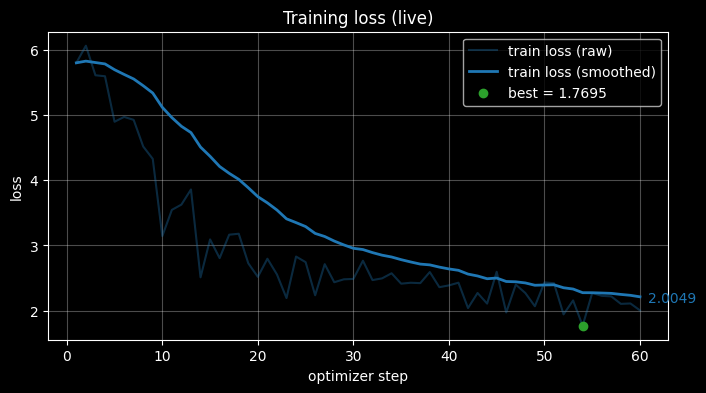

Unsloth: Restored added_tokens_decoder metadata in outputs\checkpoint-60\tokenizer_config.json.


In [25]:
trainer_stats = trainer.train()

In [26]:
# @title Show final memory and time stats
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
used_memory_for_lora = round(used_memory - start_gpu_memory, 3)
used_percentage = round(used_memory / max_memory * 100, 3)
lora_percentage = round(used_memory_for_lora / max_memory * 100, 3)
print(f"{trainer_stats.metrics['train_runtime']} seconds used for training.")
print(f"{round(trainer_stats.metrics['train_runtime'] / 60, 2)} minutes used for training.")
print(f"Peak reserved memory = {used_memory} GB.")
print(f"Peak reserved memory for training = {used_memory_for_lora} GB.")
print(f"Peak reserved memory % of max memory = {used_percentage} %.")
print(f"Peak reserved memory for training % of max memory = {lora_percentage} %.")

273.7361 seconds used for training.
4.56 minutes used for training.
Peak reserved memory = 2.262 GB.
Peak reserved memory for training = 0.256 GB.
Peak reserved memory % of max memory = 56.55 %.
Peak reserved memory for training % of max memory = 6.4 %.


### Training-loss summary

The live graph is replaced by the final summary once training finishes. It uses
the same smoothing and marks the best loss reached during the run.

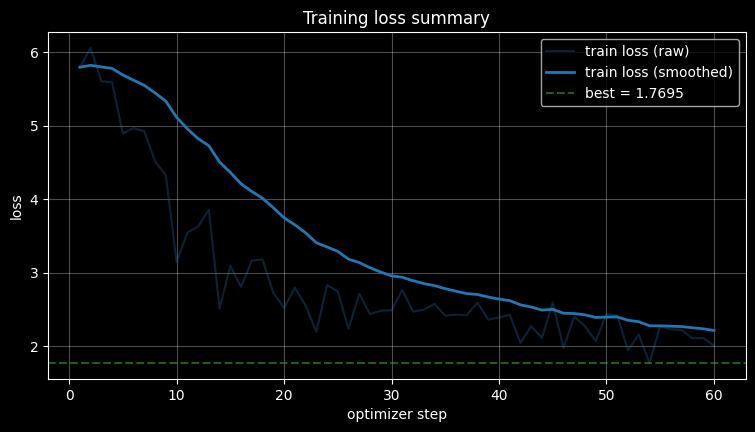

first loss = 5.7984
last loss  = 2.0049
best loss  = 1.7695
reduction  = 69.5%


In [27]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
steps = [entry["step"] for entry in history if "loss" in entry]
losses = [entry["loss"] for entry in history if "loss" in entry]

assert losses, "No loss values were logged; check logging_steps in SFTConfig."

fig, ax = plt.subplots(figsize = (9, 4.5))
ax.plot(steps, losses, color = "tab:blue", alpha = 0.3, label = "train loss (raw)")

smoothed, ema = [], losses[0]
for value in losses:
    ema = 0.9 * ema + 0.1 * value
    smoothed.append(ema)
ax.plot(steps, smoothed, color = "tab:blue", linewidth = 2, label = "train loss (smoothed)")

best = min(losses)
ax.axhline(best, color = "tab:green", linestyle = "--", alpha = 0.6,
           label = f"best = {best:.4f}")
ax.set_xlabel("optimizer step")
ax.set_ylabel("loss")
ax.set_title("Training loss summary")
ax.grid(True, alpha = 0.3)
ax.legend()
plt.show()

print(f"first loss = {losses[0]:.4f}")
print(f"last loss  = {losses[-1]:.4f}")
print(f"best loss  = {best:.4f}")
print(f"reduction  = {100 * (losses[0] - best) / losses[0]:.1f}%")

## 4. Inference

Gemma 3 1B is a **text-only** model, so the chat messages use plain strings
(no image/content-list dictionaries are needed). Recommended sampling settings
for Gemma 3 are `temperature = 1.0, top_p = 0.95, top_k = 64`.

In [28]:
FastModel.for_inference(model)  # 2x faster native inference

messages = [{
    "role": "user",
    "content": "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?",
}]
inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True,
    tokenize = True,
    return_tensors = "pt",
    return_dict = True,
).to("cuda")

outputs = model.generate(
    **inputs,
    max_new_tokens = 256,
    do_sample = True,
    temperature = 1.0,
    top_p = 0.95,
    top_k = 64,
)
print(tokenizer.batch_decode(outputs, skip_special_tokens = True)[0])

Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


user
តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអ្វី?
model
ឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា ជាអត្តសញ្ញាណពណែនទំ៊ាង ដែលមានគោលជំរិតធ្វើជាអ្នកកាន់បំណាច់ប្រដុល្លារប្រាក់ ធនាគារ សម្គ្ឋាន ឬ គណ អតិ បិទ ទៅអាទសិលមាស់ ឡាន ដែលមានសមត្ថភាពជា អ្នកកាន់បំណាច់ប្រាក់ ដែលជា អតិ បិទ និង ប្រាក់ថានឹងបានបម្រៀនៅមាន ។


You can also use a `TextStreamer` for continuous inference - so you can see the
generation token by token instead of waiting for the whole output.

In [29]:
from transformers import TextStreamer

messages = [{
    "role": "user",
    "content": "តើខ្ញុំអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដកប្រាក់តាមម៉ាស៊ីនអេធីអឹមបានចំនួនប៉ុន្មាន?",
}]
inputs = tokenizer.apply_chat_template(
    messages,
    add_generation_prompt = True,
    tokenize = True,
    return_tensors = "pt",
    return_dict = True,
).to("cuda")

_ = model.generate(
    **inputs,
    max_new_tokens = 256,
    do_sample = True,
    temperature = 1.0,
    top_p = 0.95,
    top_k = 64,
    streamer = TextStreamer(tokenizer, skip_prompt = True, skip_special_tokens = True),
)

Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


លោកអាចប្រើប័ណ្ណឥណ ពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដកប្រាក់តាមម៉ាស៊ីនអេធីអឹមបានចំនួន 8000 ប៊ីង ម៉អ៊ីន។ លោកអាចប្រើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ដកប្រាក់តាមម៉ាស៊ីនអេធីអឹមបានចំនួន 8000 ប៊ីង ម៉អ៊ីនលើ ១៥២៥ ម៉អ៊ីន។


## 5. Saving and loading the fine-tuned model

To save the final model as LoRA adapters, either use Hugging Face's `push_to_hub`
for an online save or `save_pretrained` for a local save.

**[NOTE]** This only saves the LoRA adapters, not the full model.

In [30]:
model.save_pretrained("gemma-3-1b-lora")
tokenizer.save_pretrained("gemma-3-1b-lora")

# model.push_to_hub("HF_ACCOUNT/gemma-3-1b-lora", token = "hf_...")
# tokenizer.push_to_hub("HF_ACCOUNT/gemma-3-1b-lora", token = "hf_...")

Unsloth: Restored added_tokens_decoder metadata in gemma-3-1b-lora\tokenizer_config.json.


('gemma-3-1b-lora\\tokenizer_config.json',
 'gemma-3-1b-lora\\chat_template.jinja',
 'gemma-3-1b-lora\\tokenizer.json')

Now if you want to load the LoRA adapters we just saved for inference, set
`False` to `True`:

In [31]:
if False:
    # Unsloth detects adapter_config.json in this folder and loads the base
    # model plus the saved LoRA adapter automatically.
    model, tokenizer = FastModel.from_pretrained(
        model_name = "gemma-3-1b-lora",
        max_seq_length = MAX_SEQ_LENGTH,
        load_in_4bit = True,
    )
    FastModel.for_inference(model)

    messages = [{
        "role": "user",
        "content": "តើប័ណ្ណឥណពន្ធចេស៊ីប៊ី អេស៊ីលីដា ធម្មតា មានសុពលភាពប៉ុន្មានឆ្នាំ?",
    }]
    inputs = tokenizer.apply_chat_template(
        messages,
        add_generation_prompt = True,
        tokenize = True,
        return_tensors = "pt",
        return_dict = True,
    ).to("cuda")

    from transformers import TextStreamer
    _ = model.generate(
        **inputs,
        max_new_tokens = 256,
        do_sample = True,
        temperature = 1.0,
        top_p = 0.95,
        top_k = 64,
        streamer = TextStreamer(tokenizer, skip_prompt = True, skip_special_tokens = True),
    )

### Saving to float16 for vLLM

We also support saving to `float16` directly for deployment. Set `if False` to
`if True` to let it run.

In [32]:
if False:
    model.save_pretrained_merged(
        "gemma-3-1b-finetune",
        tokenizer,
        save_method = "merged_16bit",
    )

If you want to upload to your Hugging Face account, set `if False` to `if True`
and add your Hugging Face token and upload location.

In [33]:
if False:
    model.push_to_hub_merged(
        "HF_ACCOUNT/gemma-3-1b-finetune",
        tokenizer,
        save_method = "merged_16bit",
        token = "hf_...",
    )

In [34]:
if False:
    model.save_pretrained_gguf(
        "gemma-3-1b-finetune",
        tokenizer,
        quantization_method = "q8_0",
    )

Likewise, if you want to push GGUF files to your Hugging Face account, set
`if False` to `if True` and add your token and repository.

In [35]:
if False:
    model.push_to_hub_gguf(
        repo_id = "HF_ACCOUNT/gemma-3-1b-finetune-gguf",
        tokenizer = tokenizer,
        quantization_method = "q8_0",
        token = "hf_...",
    )

## Notes and troubleshooting

* **CUDA out of memory:** lower `MAX_SEQ_LENGTH` from 1024 to 512, keep
  `per_device_train_batch_size = 1`, and/or reduce `max_steps`.
* **Imports fail / version mismatch:** install the packages listed in
  `requirements.txt`, then restart the Jupyter kernel once so the installed
  versions are loaded.
* **vLLM:** not installed because it has no official Windows wheels. Native
  Unsloth inference (`model.generate`) is used instead. On Linux you can
  `pip install vllm` separately.
* **Dataset:** `dataasilida_cleaned.csv` is read with `header = None` because
  its header line is stored as a single quoted field. If you replace it with a
  normal CSV (`input,output` header), set `skiprows = 1` and keep the same code.
* **Model:** change `MODEL_NAME` to `unsloth/gemma-3-4b-it-unsloth-bnb-4bit`
  only if your GPU has enough VRAM (~10 GB+ for 4-bit LoRA training).
* **Pinned packages:** `requirements.txt` pins `torch 2.7.1+cu118`,
  `torchao 0.13.0` and `xformers 0.0.31.post1`. Newer `xformers` needs a newer
  torch and would otherwise make pip replace the CUDA build with a CPU-only
  wheel, and newer `torchao` fails to import on torch 2.7. The xformers wheel
  for this torch is built for CUDA 12.6, so it should remain uninstalled and
  Unsloth uses PyTorch SDPA.
* **Windows import order:** `pandas` is imported before Unsloth. On Windows,
  loading `pyarrow` after Unsloth's torch patches can crash the interpreter.